# 02 Painter Fig. 3 与光谱混合分析

本页从已知雪比例生成混合光谱，重新求解端元系数，检验固定雪粒径的影响。雪谱来自前页的冻结 WW80 正演；所有雪谱与石英谱使用同一 Gaussian 光谱响应卷积到 224 个 AVIRIS 波段。

线性混合模型为
$$
R_c=\sum_iF_iR_{i,c}+E_c,\qquad E_c=R_c-\widehat R_c,\qquad
\mathrm{RMS}=\sqrt{\frac1M\sum_cE_c^2}.
$$
原文模式使用 modified Gram–Schmidt 最小二乘，允许系数越界；零反射率阴影为 $1-\sum_iF_i$。覆盖比较采用阴影归一化比例，光谱重建始终使用原始系数。

In [1]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from snowmix import teaching as t

has_cjk_font = t.configure_plots()
print("绘图标签：" + ("中文" if has_cjk_font else "English（当前环境未安装中文字体）"))
from snowmix.linear import select_snow

绘图标签：中文


## 1 统一波段与构造混合谱

真实半径为 50–1500 μm、间隔 10 μm；真实雪比例为 0–1、间隔 0.01。两者组合得到 14,746 条光谱。混合真值无阴影；解混模型保留阴影补量。

In [2]:
inputs = t.synthetic_inputs(angle_deg=0, ice_option=1)
assert inputs["snow"].shape == (146, 224)
experiment = t.run_fig3(inputs)
assert experiment["observation"].shape == (14746, 224)
print("重新生成并解混：146 × 101 × 224 = 14,746 条光谱")

重新生成并解混：146 × 101 × 224 = 14,746 条光谱


## 2 固定端元与多粒径候选

左图的误差使用固定 200 μm 雪谱；右图只保留真实雪比例为 1 的样本。多粒径模型每次放入一个雪谱，并选择 RMS 最低的候选。图中的越界系数用于解释最小二乘行为，输出未裁剪。

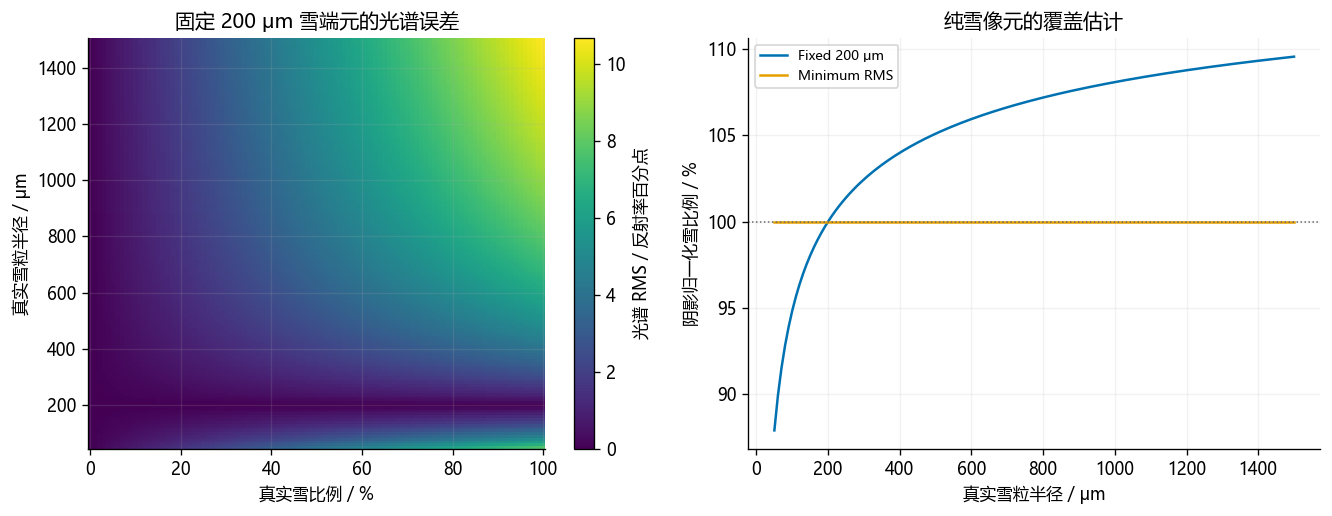

,method,bias_pp,mae_pp,rmse_pp,n,pure_snow_50um_estimate,pure_snow_50um_bias_pp,pure_snow_1500um_estimate,pure_snow_1500um_bias_pp
0,fixed,0.407764,1.697375,2.521939,14746,0.87878,-12.121978,1.095671,9.567075
1,multi,0.000000,0.000000,0.000000,14746,1.00000,0.000000,1.000000,0.000000


In [3]:
figure = t.plot_fig3(experiment)
display(figure)
plt.close(figure)
metrics = t.fig3_metrics(experiment)
display(metrics.round(6))

### 数值检查与指标对象

表中的全网格 bias 是 14,746 个案例的平均误差；两个纯雪端点 bias 分别针对 50 μm 和 1500 μm。它们描述的统计对象不同。下面用匹配端元和已知真值检查实现。

In [4]:
matching = experiment["truth_radius_um"] == 200
assert np.max(experiment["fixed"].rms[matching]) < 1e-8
assert np.max(experiment["multi"].rms) < 1e-8
np.testing.assert_allclose(experiment["multi"].normalized[:, 0], experiment["truth_fraction"], atol=1e-10)
with_snow = experiment["truth_fraction"] >= .1
np.testing.assert_array_equal(experiment["multi"].radius_um[with_snow], experiment["truth_radius_um"][with_snow])
print(f"多粒径最大 RMS = {np.max(experiment['multi'].rms):.3e}；已知比例与有雪半径检查通过。")

多粒径最大 RMS = 1.062e-15；已知比例与有雪半径检查通过。


## 3 逐波段误差项

选择一个 500 μm、真实雪比例 0.6 的合成像元。观测、重建、残差共用相同波段；残差谱揭示了 RMS 平均值背后的结构。

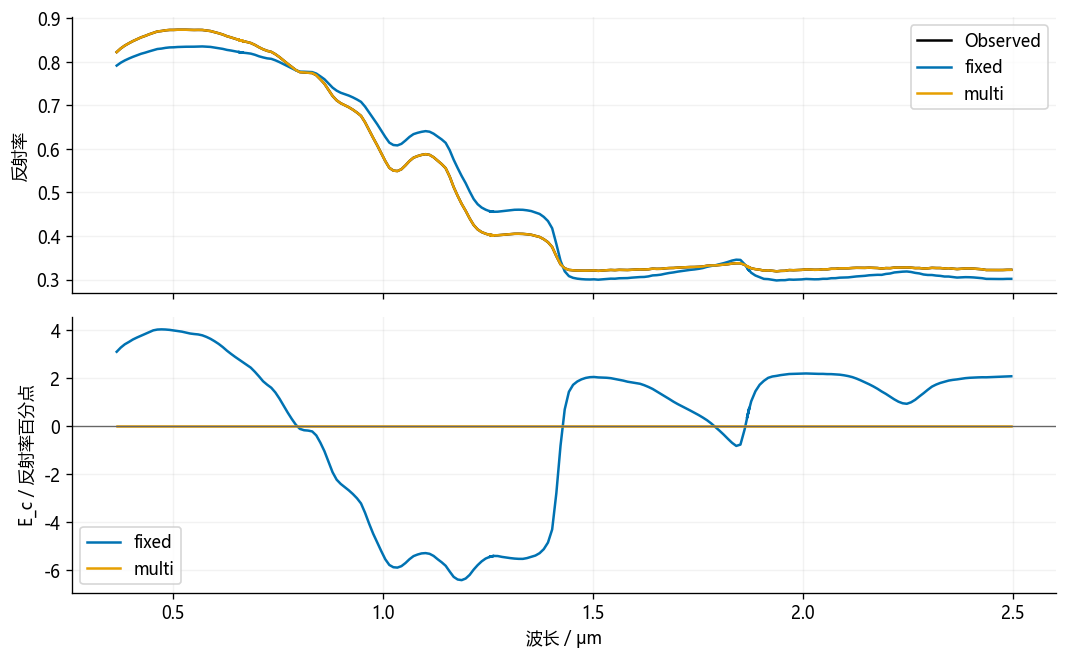

In [5]:
pixel = np.flatnonzero((experiment["truth_radius_um"] == 500) & np.isclose(experiment["truth_fraction"], .6))[0]
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True)
w = inputs["wavelength_um"]
axes[0].plot(w, experiment["observation"][pixel], color="black", label="Observed")
for key, color in zip(["fixed", "multi"], t.COLORS):
    result = experiment[key]
    np.testing.assert_allclose(result.residual, experiment["observation"] - result.modeled, atol=1e-12)
    np.testing.assert_allclose(result.rms, np.sqrt(np.mean(result.residual**2, axis=1)), atol=1e-12)
    axes[0].plot(w, result.modeled[pixel], color=color, label=key)
    axes[1].plot(w, result.residual[pixel]*100, color=color, label=key)
axes[0].set_ylabel(t.label("反射率", "Reflectance")); axes[0].legend()
axes[1].set(xlabel=t.label("波长 / μm", "Wavelength / μm"), ylabel=t.label("E_c / 反射率百分点", "E_c / reflectance pp"))
axes[1].axhline(0, color=".4", lw=.8); axes[1].legend()
fig.tight_layout(); display(fig); plt.close(fig)

## 4 FCLS 与噪声示例

FCLS 要求非阴影系数非负、总和不超过 1，剩余比例为阴影。下例使用三种半径、两种雪比例和两种阴影，加入标准差 0.005 的相同噪声，比较无约束与 FCLS。随机种子固定为 1998。

In [6]:
rng = np.random.default_rng(1998)
observations, truth = [], []
for radius in [50, 500, 1000]:
    spectrum = inputs["snow"][np.flatnonzero(inputs["radii_um"] == radius)[0]]
    for fraction in [.2, .6]:
        for shade in [0, .25]:
            observations.append((1-shade)*(fraction*spectrum + (1-fraction)*inputs["quartz"]))
            truth.append(fraction)
observations = np.asarray(observations) + rng.normal(0, .005, (12, 224))
rows = []
for solver in ["original", "fcls"]:
    result = select_snow(observations, inputs["snow"], inputs["radii_um"], inputs["quartz"], solver=solver)
    rows.append({"solver": solver, **t.difference_metrics(truth, result.normalized[:, 0]), "spectral_rms_mean": result.rms.mean()})
    if solver == "fcls":
        assert result.fractions.min() >= -1e-10
        assert result.fractions.sum(axis=1).max() <= 1 + 1e-10
display(pd.DataFrame(rows).round(6))

,solver,n,bias,mae,rmse,spectral_rms_mean
0,original,12,-0.000097,0.000542,0.000706,0.004858
1,fcls,12,-0.000141,0.000541,0.000700,0.004860


## 阅读结果

同库、同正演的无噪声案例用于检查数值实现。实景包含模型未表示的光谱与几何差异，第三份 Notebook 将观察这些差异如何影响覆盖和粒径估计。

下一步：[03 AVIRIS、MODIS 与外部验证](03_aviris_modis.ipynb)。